# Homework 2

Solution to the second homework of the Machine Learning Zoomcamp 2026, in which I explore the car fuel-efficiency dataset, inspect missing values, and perform linear regression.

## Import Libraries and Load the Data

Import NumPy, pandas, seaborn and matplotlib, load the dataset, consider only the ```engine_displacement```, ```horsepower```, ```vehicle_weight```, ```model_year``` and ```fuel_efficiency_mpg``` variables and inspect the first rows.

In [1]:
import pandas as pd
import numpy as np

import seaborn as sns
from matplotlib import pyplot as plt
%matplotlib inline

In [2]:
df = pd.read_csv("https://raw.githubusercontent.com/DataTalksClub/machine-learning-zoomcamp/refs/heads/main/cohorts/2026/data/car_fuel_efficiency_2026.csv")

In [3]:
df.head()

,model_year,origin,fuel_type,drivetrain,num_doors,engine_displacement,num_cylinders,horsepower,vehicle_weight,acceleration,fuel_efficiency_mpg
0,2006,Europe,Gasoline,Front-wheel drive,4,2180,6,243.0,3870,NaN,31.9
1,2008,Europe,Diesel,Front-wheel drive,4,2390,6,272.0,4210,NaN,31.3
2,1996,Asia,Gasoline,Front-wheel drive,5,2320,6,267.0,4240,17.3,27.5
3,1989,Europe,Gasoline,Front-wheel drive,4,2130,6,258.0,4490,18.7,28.5
4,1994,USA,Diesel,Front-wheel drive,3,2580,7,304.0,4510,17.5,31.0


In [4]:
df = df[['engine_displacement','horsepower','vehicle_weight','model_year','fuel_efficiency_mpg']]

In [5]:
df.head()

,engine_displacement,horsepower,vehicle_weight,model_year,fuel_efficiency_mpg
0,2180,243.0,3870,2006,31.9
1,2390,272.0,4210,2008,31.3
2,2320,267.0,4240,1996,27.5
3,2130,258.0,4490,1989,28.5
4,2580,304.0,4510,1994,31.0


## Data Exploration

Inspect descriptive statistics, plot the ```fuel_efficiency_mpg``` variable, check missing values (Q1).

In [6]:
df.describe()

,engine_displacement,horsepower,vehicle_weight,model_year,fuel_efficiency_mpg
count,10000.000000,9123.000000,10000.000000,10000.000000,10000.000000
mean,2268.807000,254.446016,4286.754000,1999.549500,29.997700
std,183.447355,22.844613,266.212491,14.207925,2.930245
min,1590.000000,171.000000,3320.000000,1975.000000,19.800000
25%,2150.000000,239.000000,4110.000000,1987.000000,28.000000
50%,2270.000000,254.000000,4280.000000,2000.000000,30.000000
75%,2390.000000,270.000000,4470.000000,2012.000000,31.900000
max,3110.000000,334.000000,5460.000000,2024.000000,41.200000


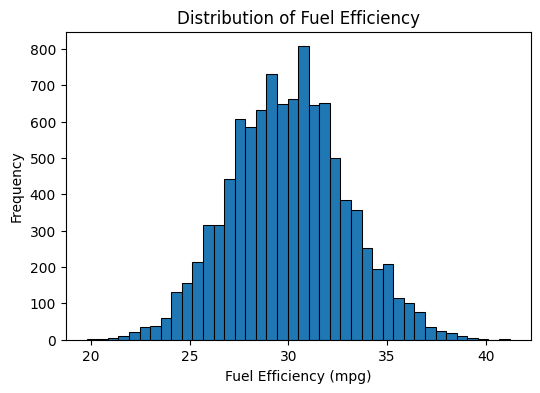

In [7]:
plt.figure(figsize=(6, 4))

sns.histplot(df.fuel_efficiency_mpg, bins=40, alpha=1)
plt.ylabel('Frequency')
plt.xlabel('Fuel Efficiency (mpg)')
plt.title('Distribution of Fuel Efficiency')

plt.show()

In [8]:
df.isnull().sum()

engine_displacement      0
horsepower             877
vehicle_weight           0
model_year               0
fuel_efficiency_mpg      0
dtype: int64

## Median Value of Horsepower

Calculate the median value of the horsepower (Q2).

In [9]:
df['horsepower'].median()

254.0

## Prepare and Split the Dataset

Shuffle and split the dataset in training data (60%), validation data (20%) and test data (20%).

In [10]:
n = len(df)
n_val = int(n * 0.2)
n_test = int(n * 0.2)
n_train = n - n_val - n_test

np.random.seed(42)
idx = np.arange(n)
np.random.shuffle(idx)

df_train = df.iloc[idx[:n_train]]
df_val = df.iloc[idx[n_train:n_train + n_val]]
df_test = df.iloc[idx[n_train + n_val:]]

In [11]:
y_train = df_train.fuel_efficiency_mpg.values
y_val = df_val.fuel_efficiency_mpg.values
y_test = df_test.fuel_efficiency_mpg.values

del df_train['fuel_efficiency_mpg']
del df_val['fuel_efficiency_mpg']
del df_test['fuel_efficiency_mpg']

## Linear Regression Comparison for Different Missing Value Filling Methods

Train linear regression models without regularization for both the case of the missing values in the ```horsepower``` column being filled with 0 and with the mean of the ```horsepower``` column and compare the RMSE of both approaches (Q3).

In [12]:
def train_linear_regression(X, y):
    ones = np.ones(X.shape[0])
    X = np.column_stack([ones, X])

    XTX = X.T.dot(X)
    XTX_inv = np.linalg.inv(XTX)
    w = XTX_inv.dot(X.T).dot(y)
    
    return w[0], w[1:]

In [13]:
def prepare_X_0(df):
    df = df.copy()
    features = ['engine_displacement','horsepower','vehicle_weight','model_year']

    df_num = df[features]
    df_num = df_num.fillna(0)
    X = df_num.values
    return X

In [14]:
def prepare_X_mean(df):
    df = df.copy()
    features = ['engine_displacement','horsepower','vehicle_weight','model_year']

    df_num = df[features]
    df_num['horsepower'] = df_num['horsepower'].fillna(df_train['horsepower'].mean())
    X = df_num.values
    return X

In [15]:
def rmse(y, y_pred):
    error = y_pred - y
    mse = (error ** 2).mean()
    return np.sqrt(mse)

In [16]:
X_train = prepare_X_0(df_train)
w_0, w = train_linear_regression(X_train, y_train)

y_pred = w_0 + X_train.dot(w)
print('train rmse using 0 to fill the missing values:', round(rmse(y_train, y_pred),3))

X_val = prepare_X_0(df_val)
y_pred = w_0 + X_val.dot(w)
print('validation rmse using 0 to fill the missing values:', round(rmse(y_val, y_pred),3))

train rmse using 0 to fill the missing values: 2.2
validation rmse using 0 to fill the missing values: 2.205


In [17]:
X_train = prepare_X_mean(df_train)
w_0, w = train_linear_regression(X_train, y_train)

y_pred = w_0 + X_train.dot(w)
print('train rmse using the mean of the training dataset to fill the missing values:', round(rmse(y_train, y_pred),3))

X_val = prepare_X_mean(df_val)
y_pred = w_0 + X_val.dot(w)
print('validation rmse using the mean of the training dataset to fill the missing values:', round(rmse(y_val, y_pred),3))

train rmse using the mean of the training dataset to fill the missing values: 2.198
validation rmse using the mean of the training dataset to fill the missing values: 2.202


The validation RMSE is approximately 2.205 when missing horsepower values are replaced with zero, and 2.202 when they are replaced with the mean calculated from the training set. The mean-imputation approach gives a slightly lower validation RMSE for this split.

## Linear Regression Comparison for Different Regularizations

Train linear regression models filling the missing values in the ```horsepower``` column with 0 for different values of the regularization constant ```r``` and compare the RMSE obtained for each of the values of ```r``` (Q4).

In [18]:
def train_linear_regression_reg(X, y, r=0.0):
    ones = np.ones(X.shape[0])
    X = np.column_stack([ones, X])

    XTX = X.T.dot(X)
    reg = r * np.eye(XTX.shape[0])
    XTX = XTX + reg

    XTX_inv = np.linalg.inv(XTX)
    w = XTX_inv.dot(X.T).dot(y)
    
    return w[0], w[1:]

In [19]:
X_train = prepare_X_0(df_train)
w_0, w = train_linear_regression_reg(X_train, y_train, 0)

X_val = prepare_X_0(df_val)
y_pred = w_0 + X_val.dot(w)
print('validation rmse using 0 to fill the missing values and r = 0:', round(rmse(y_val, y_pred),4))


w_0, w = train_linear_regression_reg(X_train, y_train, 0.01)

y_pred = w_0 + X_val.dot(w)
print('validation rmse using 0 to fill the missing values and r = 0.01:', round(rmse(y_val, y_pred),4))


w_0, w = train_linear_regression_reg(X_train, y_train, 0.1)

y_pred = w_0 + X_val.dot(w)
print('validation rmse using 0 to fill the missing values and r = 0.1:', round(rmse(y_val, y_pred),4))


w_0, w = train_linear_regression_reg(X_train, y_train, 1)

y_pred = w_0 + X_val.dot(w)
print('validation rmse using 0 to fill the missing values and r = 1:', round(rmse(y_val, y_pred),4))


w_0, w = train_linear_regression_reg(X_train, y_train, 5)

y_pred = w_0 + X_val.dot(w)
print('validation rmse using 0 to fill the missing values and r = 5:', round(rmse(y_val, y_pred),4))


w_0, w = train_linear_regression_reg(X_train, y_train, 10)

y_pred = w_0 + X_val.dot(w)
print('validation rmse using 0 to fill the missing values and r = 10:', round(rmse(y_val, y_pred),4))


w_0, w = train_linear_regression_reg(X_train, y_train, 100)

y_pred = w_0 + X_val.dot(w)
print('validation rmse using 0 to fill the missing values and r = 100:', round(rmse(y_val, y_pred),4))

validation rmse using 0 to fill the missing values and r = 0: 2.2053
validation rmse using 0 to fill the missing values and r = 0.01: 2.2058
validation rmse using 0 to fill the missing values and r = 0.1: 2.2241
validation rmse using 0 to fill the missing values and r = 1: 2.3492
validation rmse using 0 to fill the missing values and r = 5: 2.4094
validation rmse using 0 to fill the missing values and r = 10: 2.4195
validation rmse using 0 to fill the missing values and r = 100: 2.4292


The lowest value of the RMSE is obtained for ```r = 0```.

## Linear Regression Comparison for Different Random Seeds

Train linear regression models without regularization filling the missing values in the ```horsepower``` column with 0 for different random seeds, compute the RMSE obtained for each random seed and compute the standard deviation of all the scores (Q5).

In [20]:
errors = []

In [21]:
for i in range(10):
    n = len(df)
    n_val = int(n * 0.2)
    n_test = int(n * 0.2)
    n_train = n - n_val - n_test

    np.random.seed(i)
    idx = np.arange(n)
    np.random.shuffle(idx)

    df_train = df.iloc[idx[:n_train]]
    df_val = df.iloc[idx[n_train:n_train + n_val]]

    y_train = df_train.fuel_efficiency_mpg.values
    y_val = df_val.fuel_efficiency_mpg.values

    del df_train['fuel_efficiency_mpg']
    del df_val['fuel_efficiency_mpg']

    X_train = prepare_X_0(df_train)
    w_0, w = train_linear_regression(X_train, y_train)

    X_val = prepare_X_0(df_val)
    y_pred = w_0 + X_val.dot(w)
    errors.append(rmse(y_val, y_pred))

In [22]:
errors

[2.239204143046126,
 2.2021128210838845,
 2.1634197787530947,
 2.2043588768539224,
 2.2018800943311554,
 2.2457851509085134,
 2.2697212079524043,
 2.190794599933443,
 2.216611201686444,
 2.2070365928178957]

In [23]:
round(np.std(errors),3)

0.029

The standard deviation of all scores is 0.029.

## Linear Regression for Specific Values of the Parameters

Train a linear regression model with ```r = 0.001```, filling the missing values in the ```horsepower``` column with 0 and using seed 9. Compute the RMSE of the model on the test dataset (Q6).

In [24]:
n = len(df)
n_val = int(n * 0.2)
n_test = int(n * 0.2)
n_train = n - n_val - n_test

np.random.seed(9)
idx = np.arange(n)
np.random.shuffle(idx)

df_train = df.iloc[idx[:n_train + n_val]]
df_test = df.iloc[idx[n_train + n_val:]]

In [25]:
y_train = df_train.fuel_efficiency_mpg.values
y_test = df_test.fuel_efficiency_mpg.values

del df_train['fuel_efficiency_mpg']
del df_test['fuel_efficiency_mpg']

In [26]:
X_train = prepare_X_0(df_train)
w_0, w = train_linear_regression_reg(X_train, y_train, 0.001)

X_test = prepare_X_0(df_test)
y_pred = w_0 + X_test.dot(w)
print('test rmse using 0 to fill the missing values and r = 0.001:', round(rmse(y_test, y_pred),3))

test rmse using 0 to fill the missing values and r = 0.001: 2.236
